# Lista de Exercício 6
### Visão Computacional (SEL0339/SEL5886)

**Instruções:**

 1. Esta lista consiste de 5 exercícios.
 1. Deve-se colocar comentários nos códigos desenvolvidos.
 1. As perguntas devem ser respondidas também como comentários no arquivo.
 1. Colocar seu nome e número USP abaixo.
 1. Quaisquer problemas na execução das listas, entrar em contato com os monitores.
 1. Depois de terminado os exercícios, deve ser gerado um arquivo **extensão .ipynb** para ser enviado ao professor pelo E-DISCIPLINAS da disciplina até a data máxima de entrega.
 1. Caso não seja enviado, o aluno ficará sem nota.


---


 <table class="tfo-notebook-buttons" align="left">
  <td>
    <a target="_blank" href="https://colab.research.google.com/github/LAVI-Disciplinas/SEL0339-SEL5886_2026/blob/main/praticas/Lista_de_Exercicio_6.ipynb"><img src="https://www.tensorflow.org/images/colab_logo_32px.png" />Executar no Google Colab</a>
  </td>
  <td>
    <a target="_blank" href="https://github.com/LAVI-Disciplinas/SEL0339-SEL5886_2026/blob/main/praticas/Lista_de_Exercicio_6.ipynb"><img src="https://www.tensorflow.org/images/GitHub-Mark-32px.png" />Ver codigo fonte no GitHub</a>
  </td>
</table>

`Nome: `

`Número USP: `

### Dependências e imports

Execute a célula de instalação uma vez, se necessário. Em seguida, todos os imports utilizados na lista estão reunidos na célula seguinte.

In [1]:
%pip install -q ucimlrepo xgboost tensorflow

In [2]:
# Manipulação de dados e visualização
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carregamento dos conjuntos de dados
from ucimlrepo import fetch_ucirepo

# Pré-processamento
from sklearn.preprocessing import (
    LabelEncoder, OneHotEncoder, OrdinalEncoder,
    MinMaxScaler, StandardScaler, RobustScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Divisão dos dados, modelos e métricas
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Redes neurais
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import mnist
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

### Introdução

Nesta lista serão abordados tópicos de classificação de padrões, pré-processamento de dados e redes neurais. Serão utilizados os conjuntos Iris, além do MNIST para os exercícios de redes neurais.

O MNIST contém imagens de dígitos escritos à mão. O objetivo é classificar cada imagem em uma das dez classes (dígitos de 0 a 9).

Vamos utilizar dois conjuntos de dados disponíveis no [UCI Machine Learning Repository](https://archive.ics.uci.edu/). Eles podem ser baixados diretamente ou carregados com a biblioteca `ucimlrepo`.

## **Iris dataset**
O conjunto de dados **Iris**, disponibilizado no UCI Machine Learning Repository, é amplamente utilizado em estudos de aprendizado de máquina para problemas de classificação supervisionada. Ele contém **150 amostras de flores**, divididas igualmente entre três espécies: *Iris-setosa*, *Iris-versicolor* e *Iris-virginica*.

Cada amostra possui quatro atributos numéricos (medidos em centímetros):

- **Sepal length:** comprimento da sépala.
- **Sepal width:** largura da sépala.
- **Petal length:** comprimento da pétala.
- **Petal width:** largura da pétala.

A variável-alvo (*target*) é a coluna `class`, que identifica a espécie de cada flor. Portanto, temos quatro atributos de entrada (`X_iris`) e um rótulo de saída (`y_iris`), com três classes possíveis.

O objetivo é utilizar as medidas das flores para treinar modelos capazes de classificar automaticamente sua espécie.
Execute a célula abaixo para carregar e visualizar os dados.

In [3]:
# Carregando o conjunto Iris
iris = fetch_ucirepo(id=53)

X_iris = iris.data.features
y_iris = iris.data.targets

display(X_iris.head())
display(y_iris.head())

,sepal length,sepal width,petal length,petal width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,class
0,Iris-setosa
1,Iris-setosa
2,Iris-setosa
3,Iris-setosa
4,Iris-setosa


# 1) Codificação dos atributos e da variável resposta (2/10)

Modelos de aprendizado de máquina geralmente exigem que os atributos categóricos sejam representados numericamente. A escolha da codificação depende do significado das categorias:

- **Label Encoding:** atribui um número inteiro a cada classe. É útil para codificar a variável resposta (rótulos), mas pode sugerir uma ordem artificial se aplicado a atributos nominais.
- **One-hot Encoding:** cria uma coluna binária para cada categoria. É adequado para atributos nominais sem ordem natural, como tipo de dor.
- **Ordinal Encoding:** representa categorias por números que respeitam uma ordem conhecida. Deve ser usado somente quando essa ordem realmente existe.

**Tarefa:** No conjunto Iris, codifique a variável resposta, class, justificando a escolha para o tipo de Encoding usado. Verifique também se há valores ausentes. Printe o vetor com os dados codificados. Ele segue a mesma ordem das classes do vetor y_iris? Qual número corresponde a qual classe?
Salve uma variável com os dados codificados, pois eles serão usados posteriormente para treino de classificadores.

Exemplos de uso:

```python
# Codificar rótulos de uma variável resposta
encoder_y = LabelEncoder()
y_encoded = encoder_y.fit_transform(y.squeeze())

# Codificar atributos nominais em colunas binárias
encoder_x = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_encoded = encoder_x.fit_transform(X_categorico)

# Codificar categorias que possuem uma ordem definida
encoder_ord = OrdinalEncoder()
X_ord = encoder_ord.fit_transform(X_ordinal)
```

In [4]:
## -- Seu código começa AQUI -- ##

## -- Seu código termina AQUI -- ##


## -- COMENTÁRIOS -- ##

# 2) Ajuste de valores nos atributos (Pré-processamento) (2/10)

## Por que normalizar os dados?

Em conjuntos de dados reais, os atributos (*features*) frequentemente apresentam escalas e unidades de medida diferentes. Por exemplo, no conjunto **Heart Disease**, podemos encontrar atributos como idade (anos), colesterol (mg/dL), pressão arterial (mmHg) e número de vasos sanguíneos (0 a 3).

Essa diferença de escala pode prejudicar o desempenho de determinados algoritmos de aprendizado de máquina. Isso acontece porque alguns modelos utilizam cálculos matemáticos nos quais atributos com valores numericamente maiores podem exercer influência desproporcional sobre os resultados.

Considere um exemplo simplificado:

| Paciente | Idade (anos) | Colesterol (mg/dL) |
|---|---:|---:|
| A | 40 | 180 |
| B | 60 | 240 |
| C | 70 | 300 |

Em algoritmos baseados em distância, como KNN, a diferença de colesterol pode dominar o cálculo da distância em relação à diferença de idade. Consequentemente, o algoritmo pode atribuir maior importância ao colesterol simplesmente porque seus valores possuem uma magnitude numérica maior.

A normalização (*feature scaling*) busca colocar os atributos em escalas comparáveis, evitando que diferenças nas unidades de medida influenciem indevidamente o aprendizado.

Esse procedimento é especialmente importante para:

- **KNN:** utiliza distâncias entre amostras para identificar vizinhos.
- **SVM:** pode ser bastante sensível à escala dos atributos, especialmente com kernels.
- **Redes neurais:** pode facilitar a otimização e melhorar a estabilidade do treinamento.
- **Regressão logística:** pode melhorar a convergência e a estabilidade numérica.

Por outro lado, algoritmos baseados em árvores de decisão, como Decision Tree e Random Forest, geralmente são menos sensíveis à escala dos atributos, pois utilizam divisões baseadas em limiares.

##Principais técnicas de normalização

Existem diferentes técnicas de transformação dos dados. Cada uma apresenta características próprias e pode ser mais adequada dependendo da distribuição dos atributos e da presença de valores extremos (*outliers*).

### A) Normalização Min-Max

Transforma os valores de cada atributo para um intervalo definido, geralmente [0, 1].
$$
X_{norm} = \frac{X-X_{min}}{X_{max}-X_{min}}
$$
O menor valor de cada atributo passa a ser 0 e o maior passa a ser 1. Os demais valores são distribuídos proporcionalmente nesse intervalo.

**Características:**
- Preserva a distribuição original dos dados.
- Mantém a relação proporcional entre os valores.
- É sensível a valores extremos, pois utiliza mínimo e máximo.
- Pode ser interessante para algoritmos que se beneficiam de intervalos limitados.

### B) Padronização Z-score (StandardScaler)

Transforma os atributos para que apresentem média próxima de zero e desvio padrão próximo de um.

$$
Z = \frac{X-\mu}{\sigma}
$$

Em que $$\mu$$ é a média do atributo e $$\sigma$$ é desvio padrão do atributo.

Diferentemente do Min-Max, os valores não ficam limitados a um intervalo específico.

**Características:**
- Centraliza os dados em torno de zero.
- Produz atributos com variância unitária.
- É sensível a valores extremos, pois utiliza média e desvio padrão.
- É bastante utilizado em algoritmos como SVM, KNN e regressão logística.

## 2.1) Separação dos dados em treino e teste (*Train-Test Split*)

Antes de treinar um modelo de Machine Learning, precisamos dividir o conjunto de dados em duas partes:

- **Treino (*Training Set*):** utilizado para ensinar o modelo, permitindo que ele aprenda padrões e relações entre os atributos e os rótulos.
- **Teste (*Testing Set*):** utilizado para avaliar o desempenho do modelo em dados que ele ainda não conhece.

Essa separação é importante para verificar se o modelo consegue **generalizar**, ou seja, realizar boas previsões em novas amostras, e não apenas memorizar os exemplos utilizados no treinamento.

### Implementação com Scikit-learn

Podemos utilizar a função `train_test_split()` para realizar essa divisão.

```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
)
```

Parâmetros:

- `X`: atributos (*features*) do conjunto de dados.
- `y`: rótulos (*labels*) das amostras.
- `test_size=0.2`: reserva 20% dos dados para teste e utiliza 80% para treino.
- `random_state=42`: garante que a divisão seja reproduzível.

### Verificando a divisão

```python
print("Treino:", X_train.shape)
print("Teste:", X_test.shape)

print("Rótulos de treino:", y_train.shape)
print("Rótulos de teste:", y_test.shape)
```

**Atividade:** Divida o conjunto de dados Iris  em 80% para treinamento e 20% para teste. Verifique as dimensões dos conjuntos resultantes e a distribuição das classes em cada divisão.

In [5]:
## -- Seu código começa AQUI -- ##

## -- Seu código termina AQUI -- ##


## -- COMENTÁRIOS -- ##.

## 2.2) Normalização utilizando Scikit-learn

O Scikit-learn disponibiliza diferentes normalizadores (*scalers*) para transformar os atributos dos conjuntos de dados, colocando-os em escalas comparáveis.

Os principais normalizadores são:

- **MinMaxScaler:** transforma os valores para um intervalo definido, geralmente entre 0 e 1.
- **StandardScaler:** realiza a padronização Z-score, deixando os atributos com média 0 e desvio-padrão 1.

### Implementação

**1. MinMaxScaler — Normalização Min-Max**

Transforma os atributos para o intervalo entre 0 e 1.

```python
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

**2. StandardScaler — Padronização Z-score**

Realiza a padronização Z-score, deixando os atributos com média 0 e desvio-padrão 1.

```python
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
```

### Atenção: vazamento de dados (*Data Leakage*)

O normalizador deve ser ajustado somente com os dados de treino. Isso evita que informações estatísticas dos dados de teste influenciem o treinamento do modelo.

- `fit_transform()`: calcula os parâmetros do normalizador utilizando os dados de treino e realiza a transformação.
- `transform()`: aplica a transformação utilizando os parâmetros já calculados.

**Procedimento correto:**

```python
scaler = StandardScaler()

# Ajusta e transforma os dados de treino
X_train_scaled = scaler.fit_transform(X_train)

# Utiliza os mesmos parâmetros nos dados de teste
X_test_scaled = scaler.transform(X_test)
```
**Atenção:** ajuste o scaler somente com os dados de treino (`fit_transform`) e use o mesmo scaler para transformar os dados de teste (`transform`). Isso evita vazamento de informação.

**Tarefa:** Usando os métodos de normalização e padronização dos dados do sklearn, normalize os dados do conjunto de dados iris. Printe os novos dados e seus valores de máximo, mínimo, variância e desvio padrão. O que mudou nos dados?

Você pode usar a biblioteca numpy para calcular a media, desvio padrão, mínimo e máximo para cada coluna dos dados:

```python
# Média
media = np.mean(X_train, axis=0)

# Desvio-padrão
desvio = np.std(X_train, axis=0)

# Valor mínimo
minimo = np.min(X_train, axis=0)

# Valor máximo
maximo = np.max(X_train, axis=0)

```

Salve os dados em variáveis, pois você irá usá-los para treinar classificadores.

In [6]:
## -- Seu código começa AQUI -- ##

## -- Seu código termina AQUI -- ##


## -- COMENTÁRIOS -- ##

# 3.1) Modelos de Classificação (1/10)

Nesta etapa serão comparados três classificadores supervisionados usando os conjuntos Iris e Heart Disease.

- **KNN (K-Nearest Neighbors):** classifica uma amostra considerando as classes de seus *k* vizinhos mais próximos. Como depende de distâncias, costuma se beneficiar da padronização. Para instanciar e treinar:

```python
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
```

- **Random Forest:** conjunto de árvores de decisão treinadas com amostras e subconjuntos de atributos. A previsão final combina as previsões das árvores. Não exige padronização dos atributos:

```python
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)
```

- **XGBoost:** método de *boosting* que constrói árvores sequencialmente, cada uma procurando corrigir erros das anteriores:

```python
xgb = XGBClassifier(n_estimators=100, eval_metric="mlogloss",
                    random_state=42)
xgb.fit(X_train, y_train)
y_pred = xgb.predict(X_test)
```

**Tarefa:** treine os três modelos no conjunto de dados iris, utilizando os dados que você normalizou no exercício anterior para preparar os atributos. Escolha o tipo de normalização que preferir. Compare as acurácias. Use a divisão treino/teste realizada anteriormente. Qual modelo se saiu melhor?

A acurácia é a proporção de previsões corretas:

```python
y_pred = modelo.predict(X_test)
acc = accuracy_score(y_test, y_pred)
print("Acurácia:", acc)
```

In [7]:
## -- Seu código começa AQUI -- ##

## -- Seu código termina AQUI -- ##


## -- COMENTÁRIOS -- ##

# 3.2) Comparação sem normalização (1/10)

Repita os treinamentos do exercício anterior utilizando os atributos numéricos codificados, nos dados sem normalização.

Compare as acurácias com os resultados obtidos anteriormente. Quais modelos tiveram maior alteração? Explique por que a escala dos atributos pode afetar alguns classificadores mais do que outros.

In [8]:
## -- Seu código começa AQUI -- ##

## -- Seu código termina AQUI -- ##


## -- COMENTÁRIOS -- ##

## 4) Multi Layer Perceptron (MLP) (2/10)

O **MLP (Multi Layer Perceptron)** é uma rede neural formada por camadas densas (*fully connected*). Cada neurônio recebe as saídas da camada anterior, aplica uma combinação ponderada e uma função de ativação, permitindo aprender relações não lineares.

Uma MLP possui três tipos de camadas:

- **Entrada:** recebe os atributos.
- **Ocultas:** aprendem padrões dos dados.
- **Saída:** produz a classificação.

### 4.1 — Construindo uma MLP

No Keras, podemos construir uma rede utilizando `Sequential` e `Dense`.

```python
modelo = keras.Sequential([
    layers.Input(shape=(4,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

modelo.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

historico = modelo.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=16
)
```

**Principais parâmetros:**

- `Dense(16)`: camada com 16 neurônios.
- `relu`: função de ativação.
- `sigmoid`: saída entre 0 e 1, utilizada em classificação binária.
- `binary_crossentropy`: função de perda para duas classes.
- `epochs`: quantidade de épocas de treinamento.
- `batch_size`: quantidade de amostras por atualização.

Para problemas com três ou mais classes, normalmente utilizamos `softmax` na saída e `sparse_categorical_crossentropy` na função de perda.

### 4.2 — Exercício: classificação do Iris

O conjunto Iris possui quatro atributos e três classes:

| Rótulo | Espécie |
|---|---|
| 0 | Iris-setosa |
| 1 | Iris-versicolor |
| 2 | Iris-virginica |

Para simplificar, transforme o problema em classificação binária:

- **Classe 0:** Iris-setosa.
- **Classe 1:** Iris-versicolor e Iris-virginica agrupadas.

Exemplo de transformação dos rótulos:

```python
y_train_bin = (y_train != 0).astype(int)
y_test_bin = (y_test != 0).astype(int)
```

### 4.3 — Tarefa

Construa pelo menos **três MLPs com arquiteturas diferentes**, utilizando os dados Iris sem normalização.

Experimente modificar:

- Número de camadas ocultas.
- Quantidade de neurônios.
- Funções de ativação (`relu` e `tanh`).
- Quantidade de épocas (30, 50 e 100).

**Sugestões de arquiteturas:**

```python
# MLP 1: uma camada oculta
layers.Dense(16, activation="relu")

# MLP 2: duas camadas ocultas
layers.Dense(32, activation="relu")
layers.Dense(16, activation="relu")

# MLP 3: três camadas ocultas
layers.Dense(64, activation="tanh")
layers.Dense(32, activation="tanh")
layers.Dense(16, activation="tanh")
```

Todas as arquiteturas devem utilizar uma camada de saída com um neurônio e ativação `sigmoid`.

### 4.4 — Avaliação e comparação

Avalie os modelos utilizando os dados de teste:

```python
loss, acc = modelo.evaluate(X_test, y_test_bin)

print(f"Acurácia: {acc*100:.2f}%")
```

Visualize as curvas de acurácia:

```python
plt.plot(historico.history["accuracy"], label="Treino")

plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.legend()
plt.grid()
plt.show()
```

**Questões para análise:**

1. Qual MLP apresentou a maior acurácia?
2. Aumentar o número de camadas melhorou o resultado?
3. Qual foi o efeito das funções de ativação?
4. Algum modelo apresentou *overfitting*?

**Atenção:** utilize os mesmos conjuntos de treino e teste para todos os modelos. Os dados de validação servem para acompanhar o treinamento, enquanto os dados de teste devem ser reservados para a avaliação final.

In [9]:
## -- Seu código começa AQUI -- ##

## -- Seu código termina AQUI -- ##


## -- COMENTÁRIOS -- ##

## 5) Rede Neural Convolucional (CNN) (2/10)

A **CNN (Convolutional Neural Network)** é uma rede neural especialmente utilizada para trabalhar com imagens. Diferentemente das MLPs, as CNNs exploram a estrutura espacial dos dados, aprendendo filtros capazes de identificar padrões locais, como bordas, texturas e formas.

Uma CNN geralmente possui:

- **Convolução (`Conv2D`):** aplica filtros para extrair características das imagens.
- **Pooling (`MaxPooling2D`):** reduz as dimensões espaciais, preservando características importantes.
- **Flatten:** transforma os mapas de características em um vetor.
- **Dense:** realiza a classificação a partir das características extraídas.

### 5.1 — Construindo uma CNN

Vamos utilizar o conjunto **MNIST**, que contém imagens de dígitos manuscritos de 0 a 9, com dimensões de 28 × 28 pixels.

Como existem 10 classes, utilizaremos uma camada de saída com 10 neurônios e ativação `softmax`.

```python
modelo_cnn = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, kernel_size=3, activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(10, activation="softmax")
])

modelo_cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
```

**Principais parâmetros:**

- `Conv2D(16)`: utiliza 16 filtros convolucionais.
- `kernel_size=3`: define filtros de dimensão 3 × 3.
- `MaxPooling2D(2)`: reduz as dimensões espaciais pela metade.
- `Flatten()`: transforma os mapas de características em vetor.
- `Dense(10)`: produz uma saída para cada classe.
- `softmax`: calcula as probabilidades das 10 classes.

### 5.2 — Treinamento

```python
historico = modelo_cnn.fit(
    X_train, Y_train,
    epochs=5,
    batch_size=32,
    validation_split=0.1
)
```

### 5.3 — Avaliação

Após o treinamento, avalie o desempenho utilizando os dados de teste:

```python
loss, acc = modelo_cnn.evaluate(X_test, Y_test)

print(f"Acurácia no teste: {acc*100:.2f}%")
```

### 5.4 — Visualizando a acurácia

Podemos acompanhar a evolução da acurácia nos conjuntos de treino e validação durante as épocas.

```python
plt.plot(historico.history["accuracy"], label="Treino")
plt.plot(historico.history["val_accuracy"], label="Validação")

plt.title("Acurácia durante o treinamento")
plt.xlabel("Épocas")
plt.ylabel("Acurácia")
plt.legend()
plt.grid()
plt.show()
```

### 5.5 — Exercício

Treine uma CNN para classificar as imagens do MNIST e investigue como diferentes configurações influenciam o desempenho.

**Instruções:**

1. Comece com a arquitetura apresentada.
2. Experimente aumentar a quantidade de filtros convolucionais (16, 32 e 64).
3. Modifique a quantidade de neurônios na camada densa (32 e 64).
4. Teste diferentes quantidades de épocas (5, 10 e 15).

**Questões para análise:**

1. Qual configuração apresentou a maior acurácia?
2. Aumentar a quantidade de filtros melhorou o desempenho?
3. Como a quantidade de épocas influencia a convergência?
4. Algum modelo apresentou sinais de *overfitting*?

**Atenção:** utilize os dados de validação para acompanhar o treinamento e comparar as configurações. Reserve o conjunto de teste para a avaliação final dos modelos.

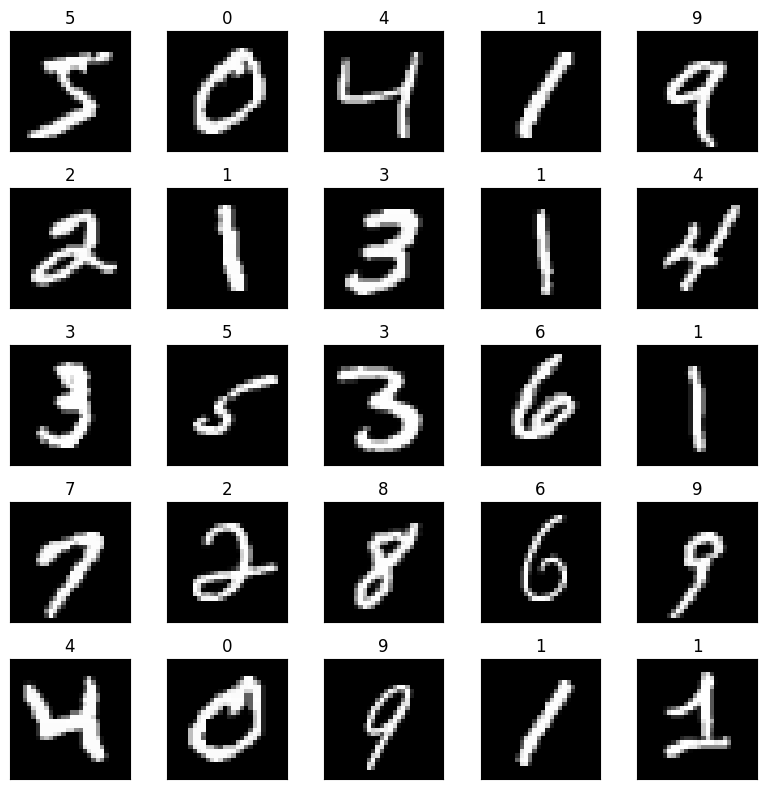

In [12]:
# Carregando o MNIST
(X_train, Y_train), (X_test, Y_test) = mnist.load_data()

# Normalizando os pixels para o intervalo [0, 1]
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Adicionando o canal de cor: (28, 28) -> (28, 28, 1)
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

# Visualizando algumas imagens
plt.figure(figsize=(8, 8))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(str(Y_train[i]))
plt.tight_layout()
plt.show()

In [11]:
## -- Seu código começa AQUI -- ##

## -- Seu código termina AQUI -- ##


## -- COMENTÁRIOS -- ##